# Dendrogram tryout

In [1]:
import comparing_and_showing as cs
import score_utils as scoring
import chunking 
import pandas as pd
import json

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/charles-/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [2]:
import nltk
nltk.download('stopwords')
nltk.download('punkt_tab')

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/charles-/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/charles-/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [ ]:
d = chunking.artist_folder_to_artist_df("Corpus/Beyonce_songs").reset_index()

56878.json
152218.json
52158.json
152215.json
4948.json
52683.json
78577.json
152213.json
75936.json
1829007.json
55885.json
68973.json
50873.json
83613.json
152217.json
80249.json


In [18]:
p = d['persona_id'].unique()

In [19]:
d[d['persona_id']==p[0]]

,index,song_id,song_title,lyricists_id,language,section_id,section_type,n_line,persona_id,text
0,0,56878,Sweet Dreams,"[498, 5898, 27667, 27690]",en,section_0,intro,0,persona_sasha_fierce,Turn the lights on
1,1,56878,Sweet Dreams,"[498, 5898, 27667, 27690]",en,section_1,verse,0,persona_sasha_fierce,"Every night, I rush to my bed"
2,2,56878,Sweet Dreams,"[498, 5898, 27667, 27690]",en,section_1,verse,1,persona_sasha_fierce,With hopes that maybe I'll get a chance
3,3,56878,Sweet Dreams,"[498, 5898, 27667, 27690]",en,section_1,verse,2,persona_sasha_fierce,To see you when I close my eyes
4,4,56878,Sweet Dreams,"[498, 5898, 27667, 27690]",en,section_1,verse,3,persona_sasha_fierce,I'm goin' out of my head
...,...,...,...,...,...,...,...,...,...,...
882,73,80249,Hello,"[498, 27678, 423220, 630785]",en,section_9,outro,0,persona_sasha_fierce,It was many years ago
883,74,80249,Hello,"[498, 27678, 423220, 630785]",en,section_9,outro,1,persona_sasha_fierce,"Baby, when you stole my cool"
884,75,80249,Hello,"[498, 27678, 423220, 630785]",en,section_9,outro,2,persona_sasha_fierce,"You had me at ""Hello"""
885,76,80249,Hello,"[498, 27678, 423220, 630785]",en,section_9,outro,3,persona_sasha_fierce,Hello


In [20]:
df_stupeflip = pd.read_csv("Corpus/Stupeflip_attribution_personas.csv")

In [4]:
def load_df(path):
    """Relit un CSV écrit par save_df."""
    df = pd.read_csv(path)
    df["lyrics"] = df["lyrics"].apply(json.loads)
    return df

In [5]:
df_kingju = load_df("Corpus/Stupeflip_Dfs/kingju.csv")
df_pophip = load_df("Corpus/Stupeflip_Dfs/pophip.csv")

In [6]:
lyrics_df_kingju = chunking.make_lyrics_dataframe(artist_dataframe=df_kingju)
lyrics_df_pophip = chunking.make_lyrics_dataframe(artist_dataframe=df_pophip)

In [7]:
chunks_kingju = chunking.format_chunk_for_scoring(lyrics_dataframe=lyrics_df_kingju, persona_id="kingju")
chunks_pophip = chunking.format_chunk_for_scoring(lyrics_dataframe=lyrics_df_pophip, persona_id="pophip")
stupeflip_chunks = chunks_kingju
stupeflip_chunks.update(chunks_pophip)

In [8]:
keys = stupeflip_chunks.keys()

In [9]:
lex_densite = {key: scoring.densite_lexicale(stupeflip_chunks[key], language="french") for key in keys}
lex_div_hdd = {key: scoring.diversite_lexicale_HDD(stupeflip_chunks[key]) for key in keys}
lex_div_mtld = {key: scoring.diversite_lexicale_MTLD(stupeflip_chunks[key]) for key in keys}


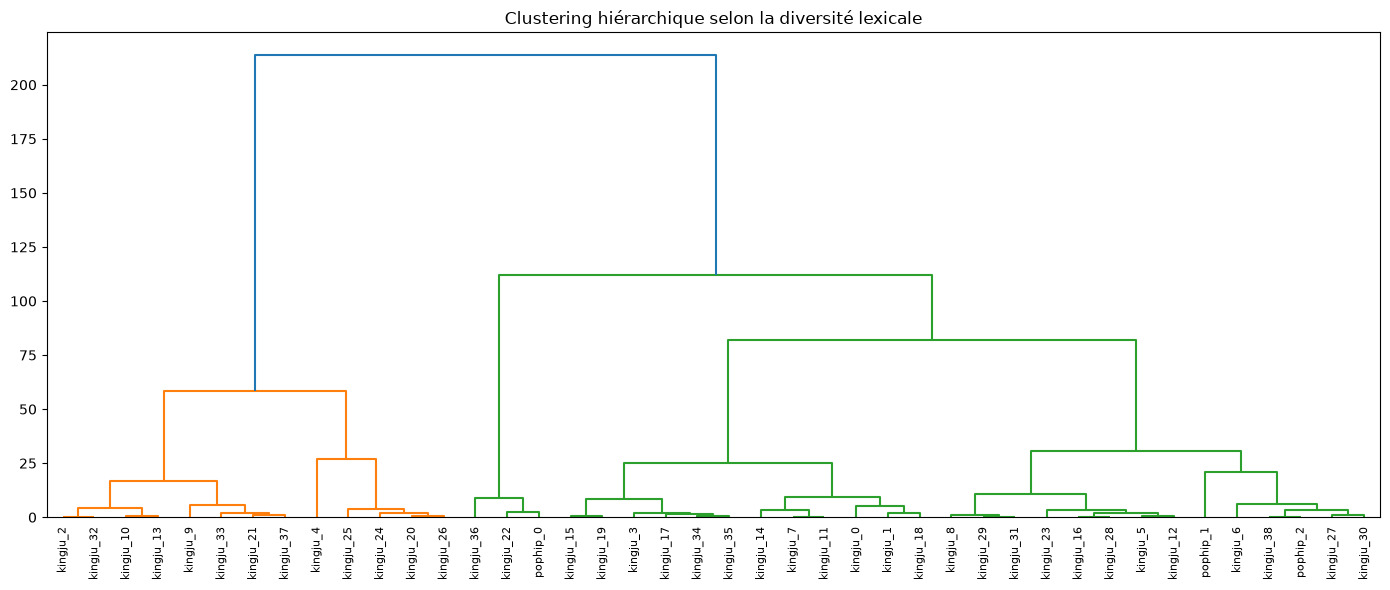

In [10]:
import numpy as np
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

labels = list(lex_div_mtld.keys())
X = np.array(list(lex_div_mtld.values())).reshape(-1, 1)  # (n_chunks, 1)

Z = linkage(X, method="ward")

plt.figure(figsize=(14, 6))
dendrogram(Z, labels=labels, leaf_rotation=90)
plt.title("Clustering hiérarchique selon la diversité lexicale")
plt.tight_layout()
plt.show()

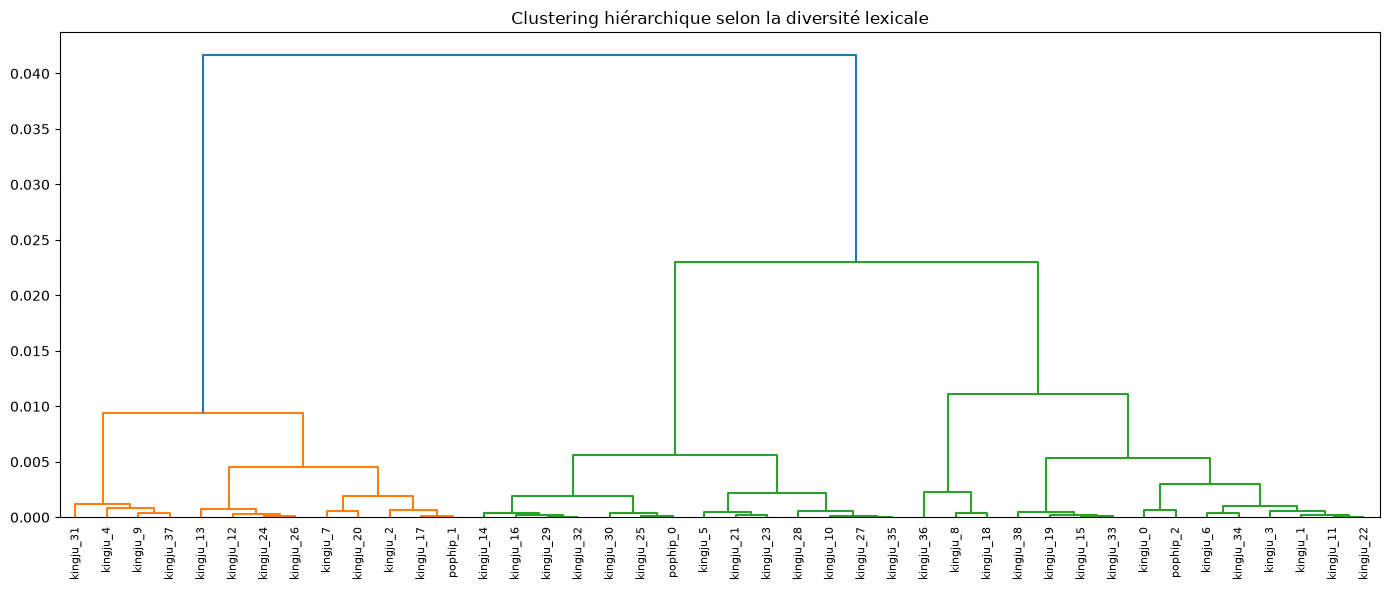

In [11]:
import numpy as np
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

labels = list(lex_div_hdd.keys())
X = np.array(list(lex_div_hdd.values())).reshape(-1, 1)  # (n_chunks, 1)

Z = linkage(X, method="ward")

plt.figure(figsize=(14, 6))
dendrogram(Z, labels=labels, leaf_rotation=90)
plt.title("Clustering hiérarchique selon la diversité lexicale")
plt.tight_layout()
plt.show()

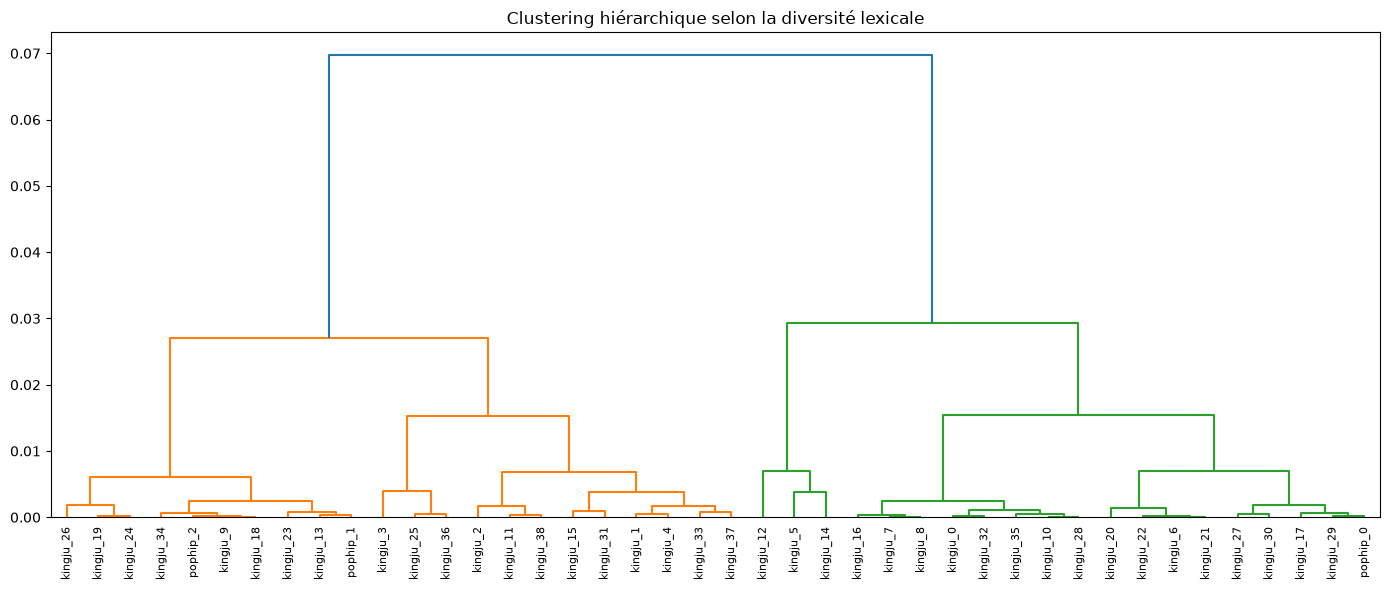

In [12]:
import numpy as np
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

labels = list(lex_densite.keys())
X = np.array(list(lex_densite.values())).reshape(-1, 1)  # (n_chunks, 1)

Z = linkage(X, method="ward")

plt.figure(figsize=(14, 6))
dendrogram(Z, labels=labels, leaf_rotation=90)
plt.title("Clustering hiérarchique selon la diversité lexicale")
plt.tight_layout()
plt.show()

In [13]:
all_lines = [line for chunk in stupeflip_chunks.values() for line in chunk]
voc = scoring.create_vocab_bow(all_lines=all_lines)
bow = {key: scoring.bow(stupeflip_chunks[key], vocab_w2i=voc) for key in keys}

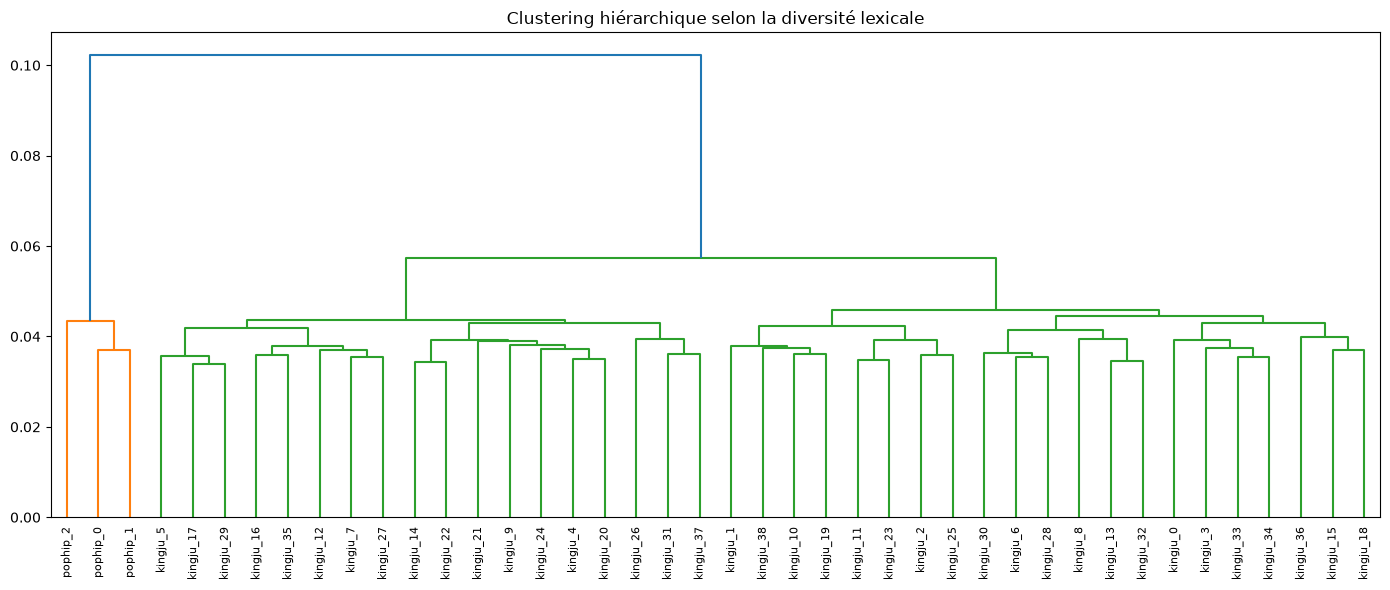

In [14]:
import numpy as np
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

labels = list(bow.keys())
X = np.array(list(bow.values())).reshape(-1, len(voc))

Z = linkage(X, method="ward")

plt.figure(figsize=(14, 6))
dendrogram(Z, labels=labels, leaf_rotation=90)
plt.title("Clustering hiérarchique selon la diversité lexicale")
plt.tight_layout()
plt.show()